In [97]:
import numpy as np
from utils.config_utils import seed_everything
from utils.data_gen_utils import create_mixing_matrix, generate_hierarchical_synthetic_data



In [98]:
# Assign parameters

seed = 10
seed_everything(seed)

# inst matrix
A_1 = np.array([
    [0, 0], 
    [0.2, 0]], 
dtype=np.float32)

A_2 = np.array([
    [0, 0], 
    [0.1, 0]], 
dtype=np.float32)

# trans matrix
B_1 = np.random.randn(2, 2).astype(np.float32)
B_2 = np.random.randn(2, 2).astype(np.float32)

C_12 = np.random.randn(2, 2).astype(np.float32)

# Mixing matrix:
H = create_mixing_matrix(4, condition_number_max=5).astype(np.float32)


In [99]:
A_list =[A_1, A_2] 
B_list = [B_1, B_2]
C_dict = {(0, 1): C_12}

X, Z = generate_hierarchical_synthetic_data(
    B_list,            # [B^{[1]}, ..., B^{[L]}]  within-layer transition matrices
    A_list,            # [A^{[1]}, ..., A^{[L]}]  within-layer INSTANTANEOUS matrices
                       # (each MUST be strictly lower triangular -> DAG within a layer)
    H,                 # concatenated true per-layer observation matrices [M_1, ..., M_L]
    C_dict=C_dict,     # {(k, l): C^{[k,l]}}  lagged cross-layer matrices, k < l only
    num_samples=10240,
    length=1,
    noise_type="sup-gauss",
    noise_scale=1.0,
    init_type="uniform",
)


In [100]:
import torch
import torch.optim as optim
import torch.nn as nn

from models.model import LinearHierarchicalTemporalICA, calc_ica_loss

x_dim = 4 
z_dim = [2, 2]

model = LinearHierarchicalTemporalICA(x_dim, z_dim)
optimizer = optim.Adam(model.parameters(), lr=5e-3)

epochs = 4000

X_tensor = torch.from_numpy(X).float()  # (n_sample, T, x_dim)
Z_tensors = [torch.from_numpy(z).float() for z in Z]  # list of (n_sample, T, z_dim) per layer

In [101]:
# Training 

kl_div_coeff = 1.0 
A_sparsity_coeff = 0.1
B_sparsity_coeff = 0.0
C_sparsity_coeff = 0.0


for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = model(torch.from_numpy(X).float())
    x_hat = outputs["x_hat"]
    z_hat = outputs["z_hat"]
    epss_hat = outputs["epss_hat"]
    
    # Compute losses
    # kl_div = torch.abs(epss_hat).mean()  # Match with the the laplace distribution 
    kl_div = calc_ica_loss(model, epss_hat)
    A_sparsity_loss = sum(torch.abs(A).mean() for A in model.A_lists) # instantaneous 
    B_sparsity_loss = sum(torch.abs(B).mean() for B in model.B_lists) # transistion
    C_sparisty_loss = sum(torch.abs(C).mean() for C in model.C_lists.get_all_matrices()) # cross-layer
    
    loss = kl_div * kl_div_coeff + \
        A_sparsity_loss * A_sparsity_coeff + \
        B_sparsity_loss * B_sparsity_coeff + \
        C_sparisty_loss * C_sparsity_coeff
    
    loss.backward()
    optimizer.step()
    
    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}, KL Div: {kl_div.item():.4f}, Sparsity Losses: A {A_sparsity_loss.item():.4f}, B {B_sparsity_loss.item():.4f}, C {C_sparisty_loss.item():.4f}")

Epoch 0, Loss: 16.9296, KL Div: 16.9296, Sparsity Losses: A 0.0000, B 1.5598, C 1.2202
Epoch 100, Loss: 12.1400, KL Div: 12.1400, Sparsity Losses: A 0.0000, B 1.4415, C 1.0296
Epoch 200, Loss: 11.0209, KL Div: 11.0209, Sparsity Losses: A 0.0000, B 1.2083, C 0.8434
Epoch 300, Loss: 10.4577, KL Div: 10.4577, Sparsity Losses: A 0.0000, B 1.3134, C 0.6375
Epoch 400, Loss: 10.1707, KL Div: 10.1707, Sparsity Losses: A 0.0000, B 1.5235, C 0.5520
Epoch 500, Loss: 10.0143, KL Div: 10.0143, Sparsity Losses: A 0.0000, B 1.7393, C 0.4809
Epoch 600, Loss: 9.9211, KL Div: 9.9211, Sparsity Losses: A 0.0000, B 1.8077, C 0.5494
Epoch 700, Loss: 9.8561, KL Div: 9.8561, Sparsity Losses: A 0.0000, B 1.7478, C 0.5751
Epoch 800, Loss: 9.8043, KL Div: 9.8043, Sparsity Losses: A 0.0000, B 1.6667, C 0.5787
Epoch 900, Loss: 9.7615, KL Div: 9.7615, Sparsity Losses: A 0.0000, B 1.5652, C 0.5755
Epoch 1000, Loss: 9.7258, KL Div: 9.7258, Sparsity Losses: A 0.0000, B 1.5138, C 0.5731
Epoch 1100, Loss: 9.6957, KL Div

In [102]:
# Evaluation 
# METRIC: MCC
from metrics.correlation_linear import compute_mcc

# 1) Get model's z_hat
model.eval()
with torch.no_grad():
    outputs = model(torch.from_numpy(X).float())
    z_hat = outputs["z_hat"].cpu().numpy()        # (n_sample, 2, sum(z_dim))


# 3) Flatten (n_sample, T) -> (n_sample*T) so each dim is one scatter
z_hat_flat  = z_hat.reshape(-1, sum(z_dim))  # (n_sample, sum(z_dim))
z_true_flat = Z.reshape(-1, sum(z_dim))  # (n_sample, sum(z_dim))

z_true_flat_mcc = z_true_flat[:1000]
z_hat_flat_mcc = z_hat_flat[:1000]

mcc = compute_mcc(z_true_flat_mcc.T, z_hat_flat_mcc.T, 'Pearson')
mcc


np.float64(0.9943014965663202)

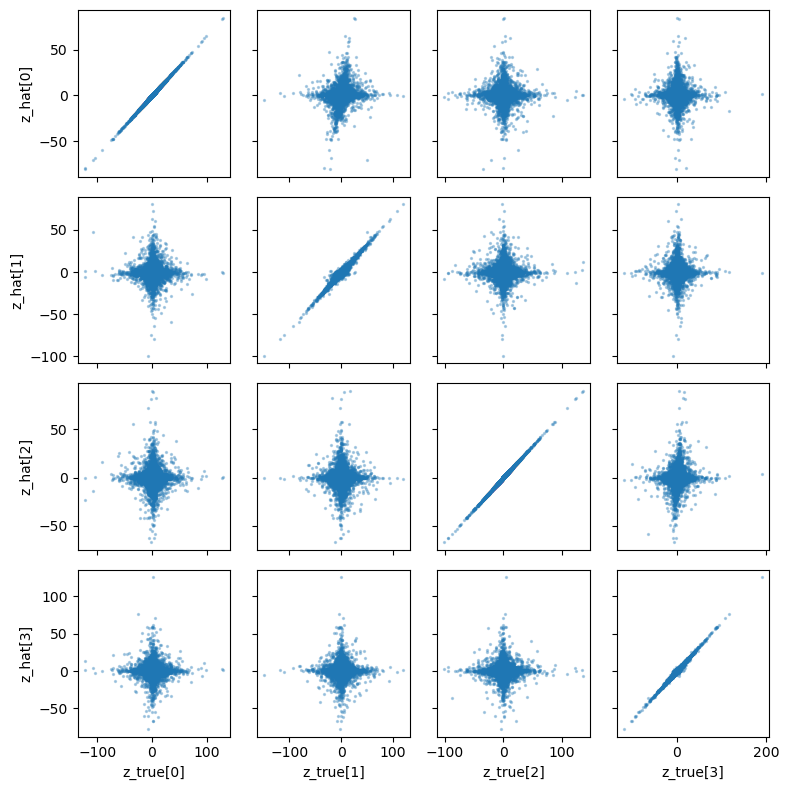

In [103]:
# Scatter plot 

import matplotlib.pyplot as plt

total_dim = z_true_flat.shape[1]              

fig, axes = plt.subplots(
    total_dim, total_dim,
    figsize=(2 * total_dim, 2 * total_dim),
    sharex="col", sharey="row",
)

for i in range(total_dim):           # row -> z_hat dim
    for j in range(total_dim):       # col -> z_true dim
        ax = axes[i, j]
        ax.scatter(z_true_flat[:, j], z_hat_flat[:, i], s=2, alpha=0.3)
        if i == total_dim - 1:
            ax.set_xlabel(f"z_true[{j}]")
        if j == 0:
            ax.set_ylabel(f"z_hat[{i}]")

plt.tight_layout()
plt.show()